# Variable Neighbourhood Search


In [4]:
import random
import math
import matplotlib.pyplot as plt

random.seed(42)


In [5]:
class Item:
    def __init__(self, item_id, weight):
        self.id = item_id
        self.weight = weight

    def __repr__(self):
        return f"Item({self.id}, {self.weight})"


class Bin:
    def __init__(self, bin_id, capacity, items=None):
        self.id = bin_id
        self.capacity = capacity
        self.items = items.copy() if items is not None else []
        self._weight = sum(it.weight for it in self.items)

    def total_weight(self):
        return self._weight

    def can_fit(self, item):
        return self._weight + item.weight <= self.capacity

    def add(self, item):
        self.items.append(item)
        self._weight += item.weight

    def pop(self, idx):
        it = self.items.pop(idx)
        self._weight -= it.weight
        return it

    def copy(self):
        b = Bin(self.id, self.capacity, self.items)
        b._weight = self._weight
        return b

    def __repr__(self):
        return f"Bin({self.id}, load={self._weight}/{self.capacity}, items={len(self.items)})"


def read_instance(filepath):
    with open(filepath) as f:
        lines = [line.strip() for line in f if line.strip()]
    n = int(lines[0])
    c = int(lines[1])
    items = [Item(i + 1, int(w)) for i, w in enumerate(lines[2:n + 2])]
    return n, c, items


In [6]:
def random_solution(items, capacity):
    shuffled = items.copy()
    random.shuffle(shuffled)
    bins = [Bin(1, capacity)]
    for item in shuffled:
        if bins[-1].can_fit(item):
            bins[-1].add(item)
        else:
            b = Bin(len(bins) + 1, capacity, [item])
            bins.append(b)
    return bins


### How to reach a neighbouring solution based on your chosen encoding?

neighbourhood operators:
1. Move: Taking an item from one bin and moving it to another bin that has enough spare capacity.
2. Swap: Exchanging two items between two bins without


In [7]:
def move_operator(bins):
    if len(bins) <= 1:
        return False
    for _ in range(30):
        src_idx = random.randrange(len(bins))
        src = bins[src_idx]
        if not src.items:
            continue
        item_idx = random.randrange(len(src.items))
        item = src.items[item_idx]

        candidates = random.sample([i for i in range(len(bins)) if i != src_idx], min(len(bins) - 1, 30))
        for dst_idx in candidates:
            dst = bins[dst_idx]
            if dst.can_fit(item):
                src.pop(item_idx)
                dst.add(item)
                if not src.items:
                    bins.pop(src_idx)
                return True
    return False


def swap_operator(bins):
    if len(bins) <= 1:
        return False
    for _ in range(30):
        i, j = random.sample(range(len(bins)), 2)
        b1, b2 = bins[i], bins[j]
        if not b1.items or not b2.items:
            continue
        u_idx = random.randrange(len(b1.items))
        v_idx = random.randrange(len(b2.items))
        u, v = b1.items[u_idx], b2.items[v_idx]

        if b1._weight - u.weight + v.weight <= b1.capacity and b2._weight - v.weight + u.weight <= b2.capacity:
            b1.items[u_idx] = v
            b1._weight += v.weight - u.weight
            b2.items[v_idx] = u
            b2._weight += u.weight - v.weight
            return True
    return False


In [8]:
def apply_k_changes(bins, k):
    new_bins = [b.copy() for b in bins]
    for _ in range(k):
        op = random.choice([move_operator, swap_operator])
        op(new_bins)
    return new_bins


def evaluate(bins):
    # minimize number of bins, maximize sum of squared bin weights to break plateaus
    return len(bins), -sum(b.total_weight() ** 2 for b in bins)


def vns(initial_bins, max_cycles=30, evals_per_k=30):
    current = [b.copy() for b in initial_bins]
    current_score = evaluate(current)
    history = [len(current)]

    for _ in range(max_cycles):
        improved = False
        k = 1
        while k <= 3:
            k_improved = False
            for _ in range(evals_per_k):
                cand = apply_k_changes(current, k)
                cand_score = evaluate(cand)
                # First improvement
                if cand_score < current_score:
                    current = cand
                    current_score = cand_score
                    history.append(len(current))
                    k_improved = True
                    improved = True
                    break
            if k_improved:
                k = 1
            else:
                k += 1
        if not improved:
            break

    return current, history


In [18]:
n_s, c_s, items_s = read_instance("data/BPP_50_200_0.2_0.7_8.txt")
init_s = random_solution(items_s, c_s)
opt_s, hist_s = vns(init_s, max_cycles=50)

lb_s = math.ceil(sum(it.weight for it in items_s) / c_s)
imp_s = len(init_s) - len(opt_s)

print(f"Small Instance:")
print(f"  Random Initial:      {len(init_s)} bins")
print(f"  VNS Optimized:       {len(opt_s)} bins")
print(f"  Theoretical Optimum: {lb_s} bins")
print(f"  Improvement:         {imp_s} bins ({imp_s / len(init_s) * 100:.1f}%)")


Small Instance:
  Random Initial:      26 bins
  VNS Optimized:       22 bins
  Theoretical Optimum: 22 bins
  Improvement:         4 bins (15.4%)


In [19]:
n_l, c_l, items_l = read_instance("data/BPP_1000_1000_0.2_0.8_5.txt")
init_l = random_solution(items_l, c_l)
opt_l, hist_l = vns(init_l, max_cycles=25)

lb_l = math.ceil(sum(it.weight for it in items_l) / c_l)
imp_l = len(init_l) - len(opt_l)

print(f"Large Instance:")
print(f"  Random Initial:      {len(init_l)} bins")
print(f"  VNS Optimized:       {len(opt_l)} bins")
print(f"  Theoretical Optimum: {lb_l} bins")
print(f"  Improvement:         {imp_l} bins ({imp_l / len(init_l) * 100:.1f}%)")


Large Instance:
  Random Initial:      709 bins
  VNS Optimized:       520 bins
  Theoretical Optimum: 504 bins
  Improvement:         189 bins (26.7%)


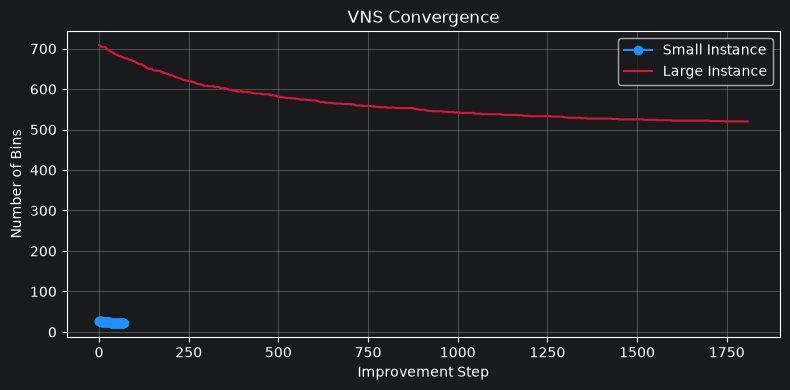

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))

# Search Progress
ax.plot(hist_s, marker='o', color='dodgerblue', label='Small Instance')
ax.plot(hist_l, color='crimson', label='Large Instance')
ax.set_title("VNS Convergence")
ax.set_xlabel("Improvement Step")
ax.set_ylabel("Number of Bins")
ax.legend()
ax.grid(True)

plt.tight_layout()
plt.show()